# The portfolio validation battery: tail back-test, convergence, additivity, recursion against Monte Carlo, correlation size and power

**Question:** Do the five tests of the portfolio battery reject a model that is wrong and accept one that is right, and what do their lights say about the five US loan types?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 02 to 05 of this topic (the fit, the copulas, CreditRisk+ and the Euler contributions)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- name the five tests of the portfolio battery, the null hypothesis of each and the rule that turns its result into a light;
- run each test on a case that it should accept and on a case that it should reject, and see what the engine returns in both;
- say what each test cannot see: how few years the tail back-test needs to reject, what a green convergence test means for a small book, what a tolerance is;
- read the size and power of the correlation estimators on the simulator grid, with the Monte Carlo standard error and the Wilson interval of every rate;
- read the committed rows of the five loan types and the simulator grid together, and say what a validator concludes from them.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# The notebook sits three folders below the repository root
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


# Names of the validation lights
LIGHTS = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Seven files of case C10, all committed (owner: this repository; the five loan-type files rest on the Federal Reserve's table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, public domain, licence class `mirror-allowed`):

- the five loan-type files `commercial-industrial.json`, `commercial-real-estate.json`, `residential.json`, `credit-cards.json` and `other-consumer.json` in `data/derived/C10/`: each carries 15 rows of `tests` (one tail back-test, twelve Euler additivity rows, one convergence row and one CreditRisk+ row), the fitted parameters and the contributions behind those rows;
- `grid-22.json` and `grid-40.json`: the **simulator grid**, the size and power of the correlation estimators on synthetic yearly default fractions drawn with a known correlation (`truth_status` is `synthetic-known-truth`): a known PD of 2%, twelve known correlations from 0.02 to 0.24, a null of 0.12, 400 replications each, series of 22 and 40 years. Each file holds 24 rows of `portfolio.correlation_size_power`, one per correlation and estimator.

The next cell loads them and counts the committed test rows by test and light.

In [2]:
# Load the seven artifacts and count the committed test rows by test and light
NAMES = {
    "commercial-industrial": "Commercial and industrial",
    "commercial-real-estate": "Commercial real estate",
    "residential": "Residential real estate",
    "credit-cards": "Credit cards",
    "other-consumer": "Other consumer",
}
read = lambda name: json.loads((ROOT / "data" / "derived" / "C10" / f"{name}.json").read_text(encoding="utf-8"))
docs = {k: read(k) for k in NAMES}
grids = {22: read("grid-22"), 40: read("grid-40")}

versions = {d["provenance"]["riskvalidation_version"] for d in [*docs.values(), *grids.values()]}
print("baked by riskvalidation", versions)
print(f"{'loan type':26s} {'rows':>5s}")
for key, label in NAMES.items():
    print(f"{label:26s} {len(docs[key]['tests']):5d}")
for years, g in grids.items():
    print(f"grid {years} years: {len(g['tests'])} rows; known PD", g["outputs"]["generator"]["known_pd"])

baked by riskvalidation {'1.0.1'}
loan type                   rows
Commercial and industrial     15
Commercial real estate        15
Residential real estate       15
Credit cards                  15
Other consumer                15
grid 22 years: 24 rows; known PD 0.02
grid 40 years: 24 rows; known PD 0.02


## Method

### Step 1: the tail back-test, and how few years it needs to reject

**H0:** the number of evaluation years above the fitted $q$-quantile is Binomial$(n, 1-q)$; the alternative is more years above it than the fit says. The p-value is the upper tail $P(X\ge\text{observed})$ at the primary level of 99% (Vasicek, 2002; Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8). **Light:** green when $p\ge0.05$, amber from 0.01 to 0.05, red below 0.01, a Contraste internal gate and not a regulatory threshold. With $n=6$ evaluation years the test has little power at 99%: a single year above the quantile gives $p=1-0.99^6=0.0585$, still green. The next cell takes the fitted PD and correlation of the commercial and industrial loans from the artifact and feeds the engine's `tail_backtest` three series of six years that it builds: all below the 99% quantile, one year above it, and two years above it. Then it runs the real evaluation years of two loan types.

In [3]:
# Run the tail back-test on constructed series and on two real loan types
from riskvalidation.engines.vasicek import lhp_quantile
from riskvalidation.validation.portfolio import tail_backtest

ml = {k: d["outputs"]["fit"]["maximum_likelihood"] for k, d in docs.items()}
pd_ci, rho_ci = ml["commercial-industrial"]["pd"]["estimate"], ml["commercial-industrial"]["rho"]["estimate"]
q99 = float(lhp_quantile(0.99, pd_ci, rho_ci))
print("fitted 99% quantile of the commercial loans:", round(q99, 5))

levels = (0.95, 0.99, 0.999)
p_by_count, light_by_count = [], []
for years_above in range(7):
    series = np.full(6, 0.004)
    series[:years_above] = 1.1 * q99
    res = tail_backtest(series, pd_ci, rho_ci, levels=levels, primary_level=0.99)
    p_by_count.append(res.p_value)
    light_by_count.append(res.light.value)
    print(f"{years_above} years above: p {res.p_value:.4g} | {LIGHTS[res.light.value]}")

for key in ("commercial-industrial", "residential"):
    rows = docs[key]["outputs"]["annual_rates"]
    evaluation = [r["loss_rate"] for r in rows if r["window"] == "evaluation"]
    realised = np.array([np.nan if v is None else v for v in evaluation])
    pd_k, rho_k = ml[key]["pd"]["estimate"], ml[key]["rho"]["estimate"]
    res = tail_backtest(realised, pd_k, rho_k, levels=levels, primary_level=0.99)
    print(f"{NAMES[key]:26s} observed at 99%: {int(res.statistic)} | p {res.p_value:.2e} | {LIGHTS[res.light.value]}")

fitted 99% quantile of the commercial loans: 0.03335
0 years above: p 1 | green
1 years above: p 0.05852 | green
2 years above: p 0.00146 | red
3 years above: p 1.955e-05 | red
4 years above: p 1.476e-07 | red
5 years above: p 5.95e-10 | red
6 years above: p 1e-12 | red
Commercial and industrial  observed at 99%: 0 | p 1.00e+00 | green
Residential real estate    observed at 99%: 5 | p 5.95e-10 | red


The next cell draws the p-value of the back-test against the number of years above the fitted 99% quantile, coloured by the light.

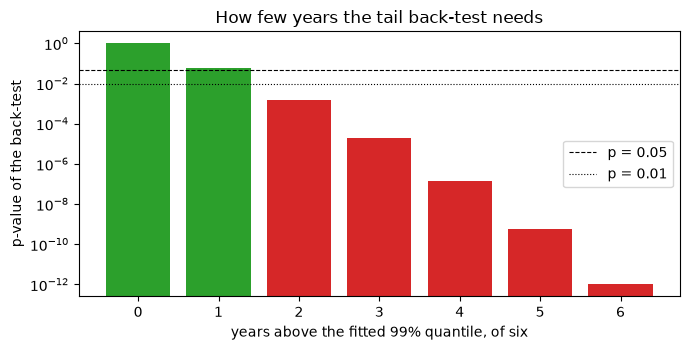

In [4]:
# Draw the back-test p-value against the number of years above the 99% quantile
colors = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(range(7), p_by_count, color=[colors[v] for v in light_by_count])
ax.axhline(0.05, color="black", linestyle="--", linewidth=0.8, label="p = 0.05")
ax.axhline(0.01, color="black", linestyle=":", linewidth=0.8, label="p = 0.01")
ax.set_yscale("log")
ax.set_xlabel("years above the fitted 99% quantile, of six")
ax.set_ylabel("p-value of the back-test")
ax.set_title("How few years the tail back-test needs")
ax.legend()
fig.tight_layout()
plt.show()

The bar for zero years is at 1, the bar for one year sits just above the 0.05 line and is still green, and from two years on the bars fall through the 0.01 line and are red. Two bad years out of six are enough to reject the fit at 99%, and one is not, so the test is blunt: it cannot flag a fit whose 99% quantile is too low by a modest amount if the six years happen to be mild. The colours follow the lights of the engine, a Contraste gate and not a regulatory threshold. The figure uses constructed series that sit exactly 10% above the quantile; real evaluation years vary in how far above they go, which the test ignores, since it only counts.

### Step 2: the Monte Carlo convergence test

**H0:** the Monte Carlo estimate equals the analytic anchor. The statistic is $z=(\text{estimate}-\text{anchor})/\mathrm{se}$ and the p-value is $2\,(1-\Phi(|z|))$, with the same green, amber and red cuts. The anchor of the portfolio battery is the large-portfolio quantile of notebook 01, exact only for a book of very many identical names: a finite book sits above it by granularity, so the test is for a book close to the limit and it is not a verdict on a real book. A non-positive standard error or a non-finite input gives `not_evaluated`, never a number. The next cell feeds `mc_convergence` the estimate, standard error and anchor of the convergence row of the case with the estimate moved by 0.5, 2.3 and 3.5 standard errors, and with a zero standard error.

In [5]:
# Run the convergence test on estimates moved by a few standard errors and on a zero standard error
from riskvalidation.validation.portfolio import mc_convergence

row = next(t for t in docs["commercial-industrial"]["tests"] if t["test_id"] == "portfolio.mc_convergence")
est, se, anchor = row["extras"]["estimate"], row["extras"]["se"], row["extras"]["anchor"]
print("estimate, standard error and anchor:", f"{est:,.0f}", f"{se:,.0f}", f"{anchor:,.0f}")

shifts = np.linspace(0.0, 4.0, 41)
p_shift = [mc_convergence(anchor + s * se, se, anchor, "var").p_value for s in shifts]
for shift in (0.5, 2.3, 3.5):
    res = mc_convergence(anchor + shift * se, se, anchor, "var")
    print(f"estimate moved by {shift} standard errors:")
    print(f"    z {res.statistic:.2f} | p {res.p_value:.4f} | {LIGHTS[res.light.value]}")
res = mc_convergence(est, 0.0, anchor, "var")
print("zero standard error:", LIGHTS[res.light.value], "| p:", res.p_value)

estimate, standard error and anchor: 2,286,000 23,604 2,298,834
estimate moved by 0.5 standard errors:
    z 0.50 | p 0.6171 | green
estimate moved by 2.3 standard errors:
    z 2.30 | p 0.0214 | amber
estimate moved by 3.5 standard errors:
    z 3.50 | p 0.0005 | red
zero standard error: not evaluated | p: None


The next cell draws the p-value of the convergence test against the displacement of the estimate in standard errors, with the amber and red cuts.

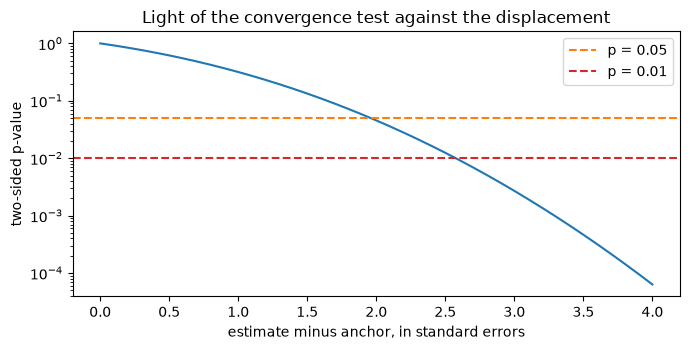

In [6]:
# Draw the convergence p-value against the displacement of the estimate
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogy(shifts, p_shift, color="tab:blue")
ax.axhline(0.05, color="tab:orange", linestyle="--", label="p = 0.05")
ax.axhline(0.01, color="tab:red", linestyle="--", label="p = 0.01")
ax.set_xlabel("estimate minus anchor, in standard errors")
ax.set_ylabel("two-sided p-value")
ax.set_title("Light of the convergence test against the displacement")
ax.legend()
fig.tight_layout()
plt.show()

The curve crosses the amber line at about two standard errors and the red line at about 2.6, so the test tolerates a displacement of two noise-sized steps and refuses beyond. It is symmetric by construction: an estimate below the anchor by the same amount gives the same p. The test says nothing about why an estimate is far from the anchor, whether the Monte Carlo is wrong, the book too small for the limit, or the standard error underestimated, which is why notebook 03 found it red for small books. A zero or negative standard error gives no p-value at all, so the curve is silent where the engine is.

### Step 3: Euler additivity, and what a tolerance is

**H0:** the Euler contributions add up to the total. The statistic is the sum, the metric is $|\text{sum}-\text{total}|/|\text{total}|$ and there is no p-value (an allocation adds up or it does not, so there is no amber): green when the metric is at most the tolerance, red above (Tasche, 2008, https://arxiv.org/abs/0708.2542). The **tolerance is the test's parameter**, and it is stated with the result: $10^{-6}$ for the ES contributions, which add up by construction, and 0.01 for the kernel VaR contributions, which are biased at the boundary. A total of zero gives `not_evaluated`. The next cell takes the committed ES contributions of the one-factor Gaussian copula at 99.9% and tests them as committed, then with one contribution inflated by 0.5% and by 2%, then with a gap of $10^{-4}$ under both tolerances.

In [7]:
# Run the additivity test on the ES contributions, on inflated ones and under the two tolerances
from riskvalidation.validation.portfolio import euler_additivity

euler_blocks = docs["commercial-industrial"]["outputs"]["euler"]
block = next(b for b in euler_blocks if b["rung_method"] == "gaussian-copula-one-factor")
level = next(lv for lv in block["levels"] if lv["level"] == 0.999)
rc_es = np.array([r["rc_es"] for r in level["rows"]])
total = level["es_total"]

res = euler_additivity(rc_es, total, 1e-6)
print("contributions:", f"{rc_es.sum():,.2f}", "| total:", f"{total:,.2f}")
print("gap:", f"{res.metric:.1e}", "|", LIGHTS[res.light.value])
for factor in (1.005, 1.02):
    inflated = rc_es.copy()
    inflated[0] *= factor
    res = euler_additivity(inflated, total, 0.01)
    print(f"first contribution x {factor}: gap {res.metric:.4f} | tolerance 0.01: {LIGHTS[res.light.value]}")
small_gap = rc_es * (1 + 1e-4)
for tol in (0.01, 1e-6):
    res = euler_additivity(small_gap, total, tol)
    print(f"all contributions x 1.0001, tolerance {tol:g}: gap {res.metric:.1e} | {LIGHTS[res.light.value]}")
res = euler_additivity(rc_es, 0.0, 1e-6)
print("total of zero:", LIGHTS[res.light.value], "| metric:", res.metric)

contributions: 3,683,187.00 | total: 3,683,187.00
gap: 0.0e+00 | green
first contribution x 1.005: gap 0.0028 | tolerance 0.01: green
first contribution x 1.02: gap 0.0111 | tolerance 0.01: red
all contributions x 1.0001, tolerance 0.01: gap 1.0e-04 | green
all contributions x 1.0001, tolerance 1e-06: gap 1.0e-04 | red
total of zero: not evaluated | metric: None


### Step 4: the CreditRisk+ recursion against Monte Carlo

**H0:** the recursion's distribution is the Monte Carlo sample's distribution of the same model. The statistic is the Kolmogorov distance $D=\max_n|F_{\text{pmf}}(n)-F_{\text{MC}}(n)|$ and the p-value comes from the asymptotic Kolmogorov law, $2\sum_{j\ge1}(-1)^{j-1}e^{-2j^2SD^2}$ (conservative for a discrete distribution); the test is red whatever the p-value if any probability of the recursion is negative, and `not_evaluated` for fewer than 10 scenarios or a sample above the grid. We rebuild the recursion input of notebook 04 and its sample (100,000 scenarios), test it, and then break it twice: a recursion run with a Gamma variance 50% too high (a wrong model, which the test should reject), and a copy of the correct probabilities with one entry set slightly negative (which the test must flag red even though its p-value does not move).

In [8]:
# Test the recursion against a sample, a wrong Gamma variance and a negative entry
from riskvalidation.portfolio import creditrisk_plus as cr
from riskvalidation.validation.portfolio import crp_recursion_vs_mc

ci_out = docs["commercial-industrial"]["outputs"]
book = ci_out["portfolio"]
crp = next(r for r in ci_out["rungs"] if r["id"] == "c4-creditrisk-plus")
sigma2 = next(p["value"] for p in crp["parameters"] if p["name"] == "sigma2")
loss_unit = next(p["value"] for p in crp["parameters"] if p["name"] == "loss_unit")
n_max = int(next(d["value"] for d in crp["diagnostics"] if d["name"] == "n_max"))
ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in book["groups"]])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in book["groups"]])
units = np.rint(ead * book["lgd_mean"] / loss_unit).astype(int)
base = dict(
    nu=units, pd=pd_names, w0=np.zeros(ead.size), weights=np.ones((ead.size, 1)),
    loss_unit=loss_unit, currency=book["currency"])
pmf = cr.pmf_stable(cr.CreditRiskPlusInput(sigma2=np.array([sigma2]), **base), n_max)
wrong = cr.pmf_stable(cr.CreditRiskPlusInput(sigma2=np.array([1.5 * sigma2]), **base), n_max)
broken = pmf.copy()
broken[5] = -1e-6
print("grid length:", n_max, "| sigma^2:", sigma2)
print("mass on the grid, correct and wrong variance:", round(float(pmf.sum()), 6), round(float(wrong.sum()), 6))

grid length: 12728 | sigma^2: 0.552065603
mass on the grid, correct and wrong variance: 1.0 1.0


The next cell draws 100,000 scenarios of the Poisson-Gamma model with the seed of the case and tests the three versions of the recursion against them.

In [9]:
# Draw the scenarios of the model and test the three versions of the recursion
rng = np.random.default_rng(np.random.PCG64(4006))
factor = rng.gamma(shape=1.0 / sigma2, scale=sigma2, size=100_000)
sample = np.zeros(factor.size, dtype=np.int64)
first = 0
for g in book["groups"]:
    sample += int(units[first]) * rng.poisson(g["n_names"] * g["pd"] * factor)
    first += g["n_names"]

cases = (
    ("the correct recursion", pmf),
    ("Gamma variance x 1.5", wrong),
    ("one negative entry", broken),
)
for label, p in cases:
    res = crp_recursion_vs_mc(p, sample)
    print(f"{label:30s} D {res.statistic:.5f} | p {res.p_value:.3e} | {LIGHTS[res.light.value]}")
    print(f"{'':30s} negative entries: {res.extras['negative_entries']}")

the correct recursion          D 0.00398 | p 8.429e-02 | green
                               negative entries: 0
Gamma variance x 1.5           D 0.06677 | p 0.000e+00 | red
                               negative entries: 0
one negative entry             D 0.00398 | p 8.416e-02 | red
                               negative entries: 1


### Step 5: the size and power of the correlation estimators

The last test is of a different kind: it evaluates an estimator, not a model. On the simulator grid, each of 400 replications draws a series of yearly default fractions with a known correlation, estimates the correlation with each of the two estimators of notebook 02, and rejects H0: $\rho=0.12$ when 0.12 lies outside the estimator's 95% interval. At the known correlation 0.12 the rejection rate is the **size**, which should equal the nominal $\alpha=0.05$; at any other known correlation it is the **power**. The engine's `correlation_size_power` takes the booleans of one cell and returns the rate, its Monte Carlo standard error $\sqrt{\hat r(1-\hat r)/R}$ and the Wilson 95% interval (Wilson, 1927, https://doi.org/10.1080/01621459.1927.10502953). At a size cell the statistic is $(\hat r-\alpha)/\sqrt{\alpha(1-\alpha)/R}$ with a two-sided normal p-value; green from 0.05, red below 0.01. At a power cell the light is green from a rate of 0.80, amber from 0.50, red below: gates of Contraste. The rate depends only on how many of the replications rejected, so the next cell rebuilds the booleans from the counts of the grid and evaluates the size cell of each estimator on the 22-year grid.

In [10]:
# Rebuild the booleans from the counts of the grid and evaluate the size cell of each estimator
from riskvalidation.validation.portfolio import correlation_size_power

gen = grids[22]["outputs"]["generator"]
print("simulator:", gen["name"], "| replications:", gen["n_replications"])
print("series length:", gen["series_length_years"])
print("null rho:", gen["null_rho"], "| alpha:", gen["alpha"], "| seed:", gen["seed"])
print(f"{'estimator':20s} {'rate':>7s} {'error std.':>10s} {'Wilson 95%':>16s} {'p':>8s} light")
for row in grids[22]["tests"]:
    extras = row["extras"]
    if extras["role"] != "size":
        continue
    flags = np.arange(row["n"]) < row["n_events"]
    res = correlation_size_power(
        flags, extras["known_rho"], extras["null_rho"], alpha=extras["alpha"], estimator=extras["estimator"])
    interval = f"{res.extras['ci_low']:.3f}-{res.extras['ci_high']:.3f}"
    head = f"{extras['estimator']:20s} {res.metric:7.4f} {res.extras['se']:10.4f} {interval:>16s}"
    print(head, f"{res.p_value:8.2e} {LIGHTS[res.light.value]}")

simulator: vasicek-lhp-simulator | replications: 400
series length: 22
null rho: 0.12 | alpha: 0.05 | seed: 7001
estimator               rate error std.       Wilson 95%        p light
maximum-likelihood    0.0525     0.0112      0.035-0.079 8.19e-01 green
moments               0.1850     0.0194      0.150-0.226 3.02e-35 red


The grid is the whole picture. The next cell draws, for the 22-year and the 40-year grids, the rejection rate of each estimator at each known correlation with its Wilson interval, the nominal 5% level, the 80% power gate and the null correlation. Where a curve is high the test sees the departure from 0.12; where it is low a validator cannot tell that correlation from 0.12 with that many years.

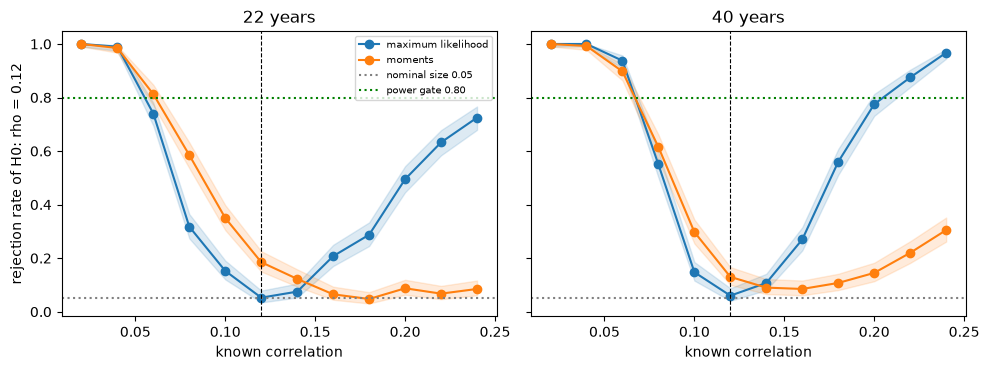

In [11]:
# Draw the rejection rate of each estimator against the known correlation for the 22- and 40-year grids
estimators = (
    ("maximum-likelihood", "tab:blue", "maximum likelihood"),
    ("moments", "tab:orange", "moments"),
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (years, g) in zip(axes, grids.items()):
    cells = g["outputs"]["cells"]
    rho_known = np.array([c["known_rho"] for c in cells])
    for name, color, label in estimators:
        picked = [next(e for e in c["estimators"] if e["estimator"] == name) for c in cells]
        rate = np.array([e["rejection_rate"] for e in picked])
        low = np.array([e["rejection_ci_low"] for e in picked])
        high = np.array([e["rejection_ci_high"] for e in picked])
        ax.plot(rho_known, rate, marker="o", color=color, label=label)
        ax.fill_between(rho_known, low, high, color=color, alpha=0.15)
    ax.axhline(0.05, color="gray", linestyle=":", label="nominal size 0.05")
    ax.axhline(0.80, color="green", linestyle=":", label="power gate 0.80")
    ax.axvline(g["outputs"]["generator"]["null_rho"], color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("known correlation")
    ax.set_title(f"{years} years")
axes[0].set_ylabel("rejection rate of H0: rho = 0.12")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

Each panel is the full size and power picture of one series length. At the dashed vertical line, the null of 0.12, an honest test rejects 5% of the time: the blue curve touches the dotted 0.05 level there and the orange one sits well above it, at about 0.19 with 22 years and 0.13 with 40. Away from the null, power is the height of the curve; it is high for correlations well below 0.12 and low for those above, where the bands are wide and the blue curve crosses the 0.80 gate only with 40 years and only at the right edge. The orange curve, the moments estimator, is not just inaccurate but biased low, so it almost never rejects above the null. The grid is synthetic with a known truth, so it measures the estimator and nothing about real data.

In [12]:
# Tabulate the rejection rates of both estimators at 22 and 40 years
rates = {}
for years, g in grids.items():
    for row in g["tests"]:
        rates[(years, row["extras"]["estimator"], row["extras"]["known_rho"])] = row["metric"]

print(f"{'known rho':>12s} {'ML 22':>7s} {'ML 40':>7s} {'moments':>12s} 22 {'moments':>12s} 40")
for rho_known in sorted({k[2] for k in rates}):
    mark = "  (null)" if abs(rho_known - 0.12) < 1e-9 else ""
    ml22, ml40 = rates[(22, "maximum-likelihood", rho_known)], rates[(40, "maximum-likelihood", rho_known)]
    mo22, mo40 = rates[(22, "moments", rho_known)], rates[(40, "moments", rho_known)]
    print(f"{rho_known:12.2f} {ml22:7.3f} {ml40:7.3f} {mo22:15.3f} {mo40:15.3f}{mark}")

   known rho   ML 22   ML 40      moments 22      moments 40
        0.02   1.000   1.000           1.000           1.000
        0.04   0.990   1.000           0.985           0.993
        0.06   0.740   0.938           0.812           0.897
        0.08   0.318   0.550           0.585           0.615
        0.10   0.152   0.147           0.350           0.297
        0.12   0.052   0.060           0.185           0.130  (null)
        0.14   0.075   0.107           0.122           0.090
        0.16   0.207   0.270           0.065           0.085
        0.18   0.287   0.560           0.048           0.107
        0.20   0.495   0.775           0.087           0.145
        0.22   0.632   0.875           0.068           0.220
        0.24   0.725   0.968           0.085           0.305


The table gives the numbers behind the curves: the rejection rate of each estimator at each known correlation, so that the size is read in the row of the null and the power in the other rows.

### Step 6: reading the committed battery

A validator reads the rows together. The next cell prints, for the five loan types, the tail back-test light, how many of the twelve Euler additivity rows are green, and the convergence and recursion lights, from the committed `tests`. Then it counts the lights of the 24 size-and-power rows of each simulator grid by estimator, so that the whole size and power picture is one table.

In [13]:
# Collect the committed lights of the five loan types and count the lights of the simulator grids
lights = {}
print(f"{'loan type':26s} {'tail':>6s} {'Euler':>12s} {'convergence':>16s} CreditRisk+")
for key, label in NAMES.items():
    by_id = {}
    for t in docs[key]["tests"]:
        by_id.setdefault(t["test_id"], []).append(t["light"])
    euler_lights = by_id["portfolio.euler_additivity"]
    z_conv = next(t["statistic"] for t in docs[key]["tests"] if t["test_id"] == "portfolio.mc_convergence")
    euler_light = "green" if euler_lights.count("green") == len(euler_lights) else "red"
    lights[key] = (
        by_id["portfolio.tail_backtest"][0], euler_light,
        by_id["portfolio.mc_convergence"][0], by_id["portfolio.crp_recursion_vs_mc"][0])
    head = f"{label:26s} {LIGHTS[lights[key][0]]:>6s} {euler_lights.count('green'):>8d} / {len(euler_lights):<2d}"
    print(head, f"{LIGHTS[lights[key][2]]:>8s} (z {z_conv:+6.1f}) {LIGHTS[lights[key][3]]:>8s}")

for years, g in grids.items():
    counts = Counter((t["extras"]["estimator"], t["extras"]["role"], t["light"]) for t in g["tests"])
    print("grid", years, "years:")
    for estimator in ("maximum-likelihood", "moments"):
        power = [counts.get((estimator, "power", light), 0) for light in ("green", "amber", "red")]
        size = next(t for t in g["tests"] if t["extras"]["estimator"] == estimator and t["extras"]["role"] == "size")
        print(f"  {estimator:20s} size {size['metric']:.4f} ({LIGHTS[size['light']]})")
        print(f"  {'':20s} power cells green/amber/red: {power[0]}/{power[1]}/{power[2]}")

loan type                    tail        Euler      convergence CreditRisk+
Commercial and industrial   green       12 / 12    green (z   -0.5)    green
Commercial real estate      green       12 / 12    green (z   -1.5)    green
Residential real estate       red       12 / 12      red (z  +23.4)    green
Credit cards                  red       12 / 12    green (z   +1.3)    green
Other consumer                red       12 / 12      red (z   +7.7)    green
grid 22 years:
  maximum-likelihood   size 0.0525 (green)
                       power cells green/amber/red: 2/3/6
  moments              size 0.1850 (red)
                       power cells green/amber/red: 3/1/7
grid 40 years:
  maximum-likelihood   size 0.0600 (green)
                       power cells green/amber/red: 5/3/3
  moments              size 0.1300 (red)
                       power cells green/amber/red: 3/1/7


The next cell draws the lights of the four consistency and outcome tests for the five loan types as a coloured grid.

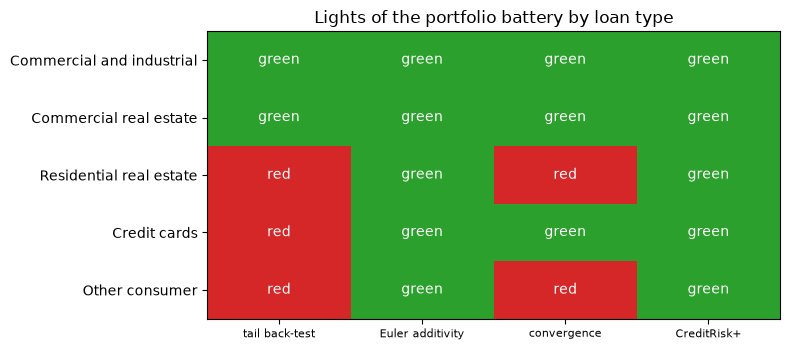

In [14]:
# Draw the lights of the four tests for the five loan types as a coloured grid
from matplotlib.colors import ListedColormap

codes = {"green": 0, "amber": 1, "red": 2}
matrix = np.array([[codes[v] for v in lights[key]] for key in NAMES])
test_labels = ["tail back-test", "Euler additivity", "convergence", "CreditRisk+"]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.imshow(matrix, cmap=ListedColormap(["tab:green", "tab:orange", "tab:red"]), vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(4), test_labels, fontsize=8)
ax.set_yticks(range(len(NAMES)), list(NAMES.values()))
for (i, j), value in np.ndenumerate(matrix):
    ax.text(j, i, LIGHTS[list(codes)[value]], ha="center", va="center", color="white")
ax.set_title("Lights of the portfolio battery by loan type")
fig.tight_layout()
plt.show()

Two columns are all green: the Euler additivity and the CreditRisk+ recursion pass for every loan type, as a correct engine must. They are consistency tests, and their green says the implementation holds together, not that the model is right. The informative columns are the other two. The tail back-test is red for residential real estate, credit cards and other consumer and green for the two commercial types; the convergence test is red for residential and other consumer. A validator reading the grid would look at the red cells first, and would remember that the red tail back-tests belong to the loan types whose fit window lacked a crisis. The grid shows lights, not magnitudes, so the numbers behind each cell are in the table above.

## Results

**Answer:** each test rejects the case built to be wrong and accepts the one built to be right: two years of six above the fitted quantile turn the tail back-test red (p = 0.0015), a Gamma variance 50% too high gives a Kolmogorov distance of 0.0668 and a p-value of 0, an estimate 3.5 standard errors from the anchor is red (p = 0.0005), and the maximum-likelihood correlation test rejects a true correlation 5.25% of the time at 22 years against 18.5% for the moments estimator; on the five loan types the tail back-test is red for residential, credit cards and other consumer.

- **The tail back-test needs two years to reject at 99%, and the real fits show the range.** With six evaluation years, no year above the fitted 99% quantile gives p = 1.0 (green), one year gives p = 0.0585, still green because it is above 0.05, and two years give p = 0.0015 (red). On the real evaluation years the commercial and industrial fit has none above (p = 1.0, green) and the residential fit has 5 of 6 (p = 6e-10, red). The test is a gate on the fit against the years that followed it, and it is the only test of the five that meets observed outcomes.
- **The convergence test passes or fails a small book, not a model.** An estimate moved by 0.5 standard errors stays green (p = 0.62), at 2.3 it is amber (p = 0.021) and at 3.5 red (p = 0.0005); a zero standard error returns `not_evaluated` and no number. In the committed rows the residential book is red at z = +23.4 and other consumer at z = +7.7, while commercial and industrial (z = -0.5), commercial real estate (z = -1.5) and credit cards (z = +1.3) are green. The notebook does not test why the two reds occur; it shows only that the 5,000-name check does not reach the large-portfolio limit at their PD and correlation, and a red here does not say the engine is wrong.
- **A tolerance is part of the result.** The ES contributions add to the total exactly (gap 0, green). One contribution inflated by 0.5% leaves a gap of 0.0028, green at the tolerance of 0.01; inflated by 2% the gap is 0.0111, red. The same relative gap of 1e-4 is green at the VaR tolerance of 0.01 and red at the ES tolerance of 1e-6. A total of zero returns `not_evaluated`. A green Euler row therefore means the allocation adds up to the stated tolerance, no more.
- **The recursion test sees a wrong model and a negative probability.** The correct recursion against its own sample has D = 0.00398 and p = 0.084 (green). A Gamma variance 50% too high gives D = 0.0668 and a p-value of 0 (red). One entry set to -1e-6 leaves D and p unchanged and the light turns red, because the rule marks any negative probability red whatever the p-value.
- **The maximum-likelihood correlation test has the right size and little power.** On the simulator at 22 years the maximum-likelihood test of rho = 0.12 rejects 5.25% of the time when it is true (standard error 1.1 points, Wilson interval 3.5% to 7.9%, p = 0.82, green) and the moments test rejects 18.5% of the time (interval 15.0% to 22.6%, p = 3e-35, red). At 40 years the sizes are 6.0% and 13.0%. A validator who rejects a correlation with the moments interval is wrong about one time in five when the correlation is true.
- **Neither test has much power against its neighbours.** With 22 years the maximum-likelihood test rejects a true correlation of 0.10 only 15% of the time and 0.14 only 7.5%; above the null it never reaches 80% at 22 years (72.5% at 0.24). At 40 years it reaches 77.5% at 0.20 and 96.8% at 0.24. The moments test, which is biased low, rejects correlations above 0.12 almost never (4.8% to 8.7% from 0.16 to 0.24 at 22 years). Of the 11 power cells at 22 years, the maximum-likelihood test is green in 2, amber in 3 and red in 6.
- **Reading the five loan types together.** All twelve Euler additivity rows of every loan type and the CreditRisk+ row are green: these are consistency gates that a correct engine passes, and they cannot tell a validator that the model is wrong. The tail back-test is red for residential, credit cards and other consumer and green for the two commercial types, and that separation, not the green rows, is the evidence about the fitted correlations of notebook 02.

What this notebook does not show: a power analysis of the tail back-test itself (six years cannot have much), the size of the other four tests, or the effect of dependent years on any of them.

## Summary

- The portfolio battery has five tests: the tail back-test (binomial on years above a fitted quantile), the Monte Carlo convergence test (z against an analytic anchor), Euler additivity (a sum within a tolerance), the CreditRisk+ recursion against Monte Carlo (Kolmogorov distance, red on a negative entry) and the size and power of a correlation estimator.
- Each returns a `TestResult` with its null hypothesis, its parameters and a light under Contraste gates; a result that cannot be evaluated is `not_evaluated`, never a number.
- The consistency tests pass on a correct engine, and the tail back-test is the one that meets outcomes and separates the loan types.
- The maximum-likelihood correlation test has the right size and low power at 22 years; the moments test over-rejects at the null and almost never rejects above it.

**What to try next.** Plant your own defect: shift one tail back-test year, change the tolerance of the additivity test, or give `crp_recursion_vs_mc` a different grid length, and see which test turns red first. Then read notebook 07 for the state of the art these tests sit in.

## References

- Wilson, E. B. (1927), Probable inference, the law of succession, and statistical inference, Journal of the American Statistical Association 22(158):209-212. https://doi.org/10.1080/01621459.1927.10502953
- Tasche, D. (2008), Capital allocation to business units and sub-portfolios: the Euler principle, arXiv 0708.2542. https://arxiv.org/abs/0708.2542
- Haaf, H., Reiss, O. and Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Kolmogorov, A. (1933) and Smirnov, N. (1948), the Kolmogorov distance and its asymptotic law, as cited by the engine's `validation.portfolio` module.
- Persisted research dossier 05 of this product (the validation of an economic capital model), section G.5, and dossier 04, section C.4.
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.